In [1]:
import pandas as pd
import zipfile
import tarfile


In [2]:
import sys
sys.path.append('../../../resources/Chinese_names_handlers/')

import characternames_handler
import pinyinnames_handler

In [3]:
import sys
sys.path.append('../../../code/')

from libs import ios


## Functions

In [4]:
def read_csv_from_zip(path_fn, filename, **kwargs):
    """
    Opens a zip file at path_fn, reads the specified filename as a CSV, and returns a DataFrame.
    Additional keyword arguments are passed to pd.read_csv.
    """
    with zipfile.ZipFile(path_fn) as z:
        with z.open(filename) as f:
            return pd.read_csv(f, **kwargs)
        
def read_csv_from_tar_gz(path_fn, filename, **kwargs):
    """
    Opens a tar.gz file at path_fn, reads the specified filename as a CSV, and returns a DataFrame.
    Additional keyword arguments are passed to pd.read_csv.
    """
    with tarfile.open(path_fn, "r:gz") as tar:
        member = tar.getmember(filename)
        f = tar.extractfile(member)
        return pd.read_csv(f, **kwargs)

In [169]:
def plot_gender_comparison(
    df,
    method_order,
    method_labels=None,
    xlabel_order=None,
    colors=None,
    use_percentages=True,
    annotate_bars=False,
    annotate_kwargs=None,
    legend_kwargs=None,
    title=None,
    figsize=(6, 4),
    **plot_kwargs,
):
    """
    Grouped bar chart comparing gender distribution across multiple methods.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the method columns.
    method_order : list of str
        Column names in the order you want for legend and bars (e.g. ["gender_clean", "gender_nq_clean", "pred_label"]).
    method_labels : dict, optional
        Map column name -> legend label (e.g. {"pred_label": "Ours"}). If None, column names are used.
    xlabel_order : list of str, optional
        Order of gender categories on x-axis (e.g. ["female", "male", "neutral", "unknown"]).
        Categories in data but not in this list are appended in sorted order.
    colors : list of str, optional
        One color per method (e.g. ["#2ecc71", "#3498db", "#e74c3c"]).
    use_percentages : bool, default True
        If True, show % within each method (each method sums to 100%); else show counts.
    annotate_bars : bool, default False
        If True, show values on top of each bar.
    annotate_kwargs : dict, optional
        Passed to ax.text() for bar labels (e.g. fontsize, ha, va).
    legend_kwargs : dict, optional
        Passed to ax.legend().
    title : str, optional
        Axes title.
    figsize : tuple, default (6, 4)
        Figure size.
    **plot_kwargs
        Additional kwargs passed to plt.subplots() (e.g. constrained_layout=True).

    Returns
    -------
    fig, ax
    """
    import matplotlib.pyplot as plt
    import numpy as np

    method_labels = method_labels or {}
    annotate_kwargs = dict(annotate_kwargs or {})
    legend_kwargs = dict(legend_kwargs or {})
    colors = colors or ["#2ecc71", "#3498db", "#e74c3c"]
    xlabel_order = xlabel_order or ["female", "male", "neutral", "unknown"]

    counts = {col: df[col].value_counts() for col in method_order}
    all_cats = set().union(*(c.index.astype(str) for c in counts.values()))
    xlabel_order = [c for c in xlabel_order if c in all_cats] + sorted(all_cats - set(xlabel_order))
    n_cats = len(xlabel_order)
    n_methods = len(method_order)
    width = 0.8 / n_methods

    if use_percentages:
        totals = {col: counts[col].sum() for col in method_order}
        data = np.array([
            [counts[col].get(cat, 0) / totals[col] * 100 for cat in xlabel_order]
            for col in method_order
        ])
        ylabel = "Percentage (%)"
    else:
        data = np.array([
            [counts[col].get(cat, 0) for cat in xlabel_order]
            for col in method_order
        ])
        ylabel = "Count"

    x = np.arange(n_cats)
    fig, ax = plt.subplots(figsize=figsize, **plot_kwargs)
    for i, col in enumerate(method_order):
        offset = (i - (n_methods - 1) / 2) * width
        bars = ax.bar(
            x + offset, data[i], width,
            label=method_labels.get(col, col),
            color=colors[i % len(colors)],
        )
        if annotate_bars:
            default_annot = {"ha": "center", "va": "bottom", "fontsize": 8}
            default_annot.update(annotate_kwargs)
            for bar, val in zip(bars, data[i]):
                if val != 0:
                    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.1f}" if use_percentages else f"{int(val)}", **default_annot)

    ax.set_xticks(x)
    ax.set_xticklabels(xlabel_order)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Gender")
    if title is not None:
        ax.set_title(title)
    ax.legend(**legend_kwargs)
    ax.autoscale(axis="y")
    plt.tight_layout()
    return fig, ax

## Constants

In [5]:
FN_APS_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip' #aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a.zip'
FN_APS_OA_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a_20250120_APSOpenAlex/final_dataset.tar.gz'

FN_CNKI_GIVENNAMES_GENDER = '../../../results/v3/gender/pinyin_infer/uniqueChineseAllGivenNames_PYgender.csv'

In [6]:
RESULTS_DIR = '../../../results/v3/APS/'
ios.validate_path(RESULTS_DIR)

In [144]:
FN_APS_CLEAN_CH_PY = ios.path_join(RESULTS_DIR, 'data_aps_clean_ch_py.csv')

## Loading data

In [7]:
_df_aps_authors = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/authors.csv')
_df_aps_authors_names = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/author_names.csv')
_df_aps_genders = read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/genders.csv')

df_aps = pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False


print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)


In [8]:
df_cnki_gender = pd.read_csv(FN_CNKI_GIVENNAMES_GENDER)
print(f"CNKI given names with gender: {df_cnki_gender.shape}")


CNKI given names with gender: (46144, 20)


In [9]:
df_aps.sample(5)

,id_author,id_author_name,name,gender,gender_nq,disambiguated
188247,147836,188247,Henri Epstein,male,gm,True
313875,252777,313875,A. Cipris,female,-,True
467973,394290,467973,E. L. Murphy,unknown,-,True
456319,383025,456319,J. T. Hickmott,unknown,-,True
779911,705696,779911,V. Sechovský,unknown,-,False


In [10]:
df_cnki_gender.sample(5)

,givenname,pop_CNKI,pop_NU,NLen,english_one,pred,pred_label,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,major_label,thres_label,label_score
17424,恒利,5.0,3666.752316,2,hengli,0.180201,male,1,0.180201,0.180201,0.180201,1,0,0,5.0,3666.752316,恒利,male,male,0.000001
17944,懂,1.0,7.412014,1,dong,0.295609,male,6,0.354659,0.368688,0.345689,5,0,1,207.0,12957.364565,东#冬#懂#栋#洞#董,male,male,0.083334
37577,长睿,1.0,2326.019379,2,changrui,0.171956,male,2,0.208832,0.191474,0.208832,2,0,0,2.0,3163.127406,常睿#长睿,male,male,0.000001
39520,麦加,1.0,437.530698,2,maijia,0.534789,neutral,2,0.626394,0.644425,0.626394,0,1,1,2.0,1089.510879,麦加#麦嘉,neutral,neutral,0.749999
33323,苏德,1.0,2790.258123,2,sude,0.379180,neutral,1,0.379180,0.379180,0.379180,0,0,1,1.0,2790.258123,苏德,neutral,neutral,0.500000


## Pre-processing

In [11]:
def _resolve_gender(labels):
    """Resolve a list of gender labels to a single value. Treat '-' as unknown."""
    # Normalize: "-" -> "unknown", strip and lower
    normalized = [
        "unknown" if str(x).strip().lower() in ("-", "unknown", "") else str(x).strip().lower()
        for x in labels
    ]
    unique = set(normalized)
    if len(unique) == 1:
        return list(unique)[0]
    # Contradiction: both male and female present -> neutral
    if "male" in unique and "female" in unique:
        return "neutral"
    # Drop unknowns and pick the non-unknown
    non_unknown = [x for x in normalized if x != "unknown"]
    if not non_unknown:
        return "unknown"
    # Only one non-unknown value (unknown was minority or tied with one known)
    if len(set(non_unknown)) == 1:
        return non_unknown[0]
    # Should not reach if logic is correct (we already handled male+female)
    return "neutral"


def clean_aps_names(df_aps):
    """
    Clean the APS names
    """

    # create new instance to modify
    data = df_aps.copy()
    
    # Aggregate: one row per id_author
    agg = (
        data
        .groupby("id_author", as_index=False)
        .agg(
            alternative_names=("name", lambda s: s.dropna().unique().tolist()),
            n_alternative_names=("name", "size"),
            genders=("gender", lambda s: s.dropna().tolist()),
            genders_nq=("gender_nq", lambda s: s.dropna().tolist()),
            gender_clean=("gender", _resolve_gender),
            gender_nq_clean=("gender_nq", _resolve_gender),
            longest_name=("name", lambda s: max(s.dropna(), key=len)),
        )
    )

    # 1. lower-case
    agg.loc[:, 'longest_name_clean'] = agg.longest_name.str.lower()

    # 2. remove accent
    agg.loc[:, 'longest_name_clean'] = agg.longest_name_clean.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

    # remove parentheses (names written in both pinyin and chinese characters)
    agg.loc[:, 'longest_name_clean'] = agg.longest_name_clean.apply(lambda x: x.replace('(', '').replace(')', '').replace(';','').strip())

    return agg


In [12]:
def detect_pinyin_and_chinese_names(df_aps_clean):
    """
    Detect the pinyin and chinese names
    """

    # 3. split givenname and familyname
    df_aps_clean.loc[:, 'givenname_clean'] = df_aps_clean.longest_name_clean.apply(lambda x: x.split(' ')[0])
    df_aps_clean.loc[:, 'familyname_clean'] = df_aps_clean.longest_name_clean.apply(lambda x: x.split(' ')[-1])

    # 4. evaluate if the given name (first name) is a pinyin given name
    df_aps_clean.loc[:, 'is_pinyin_givenname'] = df_aps_clean.givenname_clean.apply(lambda x: pinyinnames_handler.is_pinyin_givenname(x))

    # 5. evaluate if the family name is a pinyin family name
    df_aps_clean.loc[:, 'is_pinyin_familyname'] = df_aps_clean.familyname_clean.apply(lambda x: pinyinnames_handler.is_pinyin_familyname(x))

    # 6. evaluate if the name is a pinyin name (using both signals from given and family names)
    df_aps_clean.loc[:, 'is_pinyin'] = df_aps_clean.apply(lambda x: x.is_pinyin_givenname != False and x.is_pinyin_familyname and len(x.longest_name_clean.split(' ')) == 2, axis=1)

    # 7. evaluate if the name is a chinese name (using ch_name)
    df_aps_clean.loc[:, 'ch_name'] = df_aps_clean.loc[:, 'longest_name'].apply(lambda x: pd.NA if '(' not in x or ')' not in x else x.split('(')[-1].split(')')[0].replace(';','').strip())
    df_aps_clean.loc[:, "ch_splitname"] = df_aps_clean.apply(lambda row: characternames_handler.split_names(row.ch_name) if pd.notna(row.ch_name) else pd.NA, axis=1)
    df_aps_clean.loc[:, "ch_familyname"] = df_aps_clean.ch_splitname.apply(lambda x: x[0].split(' ')[0] if isinstance(x, list) and len(x) == 1 else pd.NA)
    df_aps_clean.loc[:, "ch_givenname"]  = df_aps_clean.ch_splitname.apply(lambda x: x[0].split(' ')[1] if isinstance(x, list) and len(x) == 1 else pd.NA)
    
    # 8. translate the chinese name to pinyin
    df_aps_clean.loc[:, 'ch_translated_name_in_pinyin'] = df_aps_clean.apply(lambda row: pd.NA if pd.isna(row.ch_splitname) else characternames_handler.pinyinname(row.ch_splitname)[0], axis=1)
    df_aps_clean.loc[:, 'ch_translated_familyname_in_pinyin'] = df_aps_clean.ch_translated_name_in_pinyin.apply(lambda x: x.split(' ')[0] if isinstance(x, str) else pd.NA)
    df_aps_clean.loc[:, 'ch_translated_givenname_in_pinyin'] = df_aps_clean.ch_translated_name_in_pinyin.apply(lambda x: x.split(' ')[1] if isinstance(x, str) else pd.NA)
    
    return df_aps_clean


In [13]:
df_aps_clean = clean_aps_names(df_aps)
df_aps_clean_ch_py = detect_pinyin_and_chinese_names(df_aps_clean)
df_aps_clean_ch_py.shape

(874556, 21)

In [14]:
df_aps_clean_ch_py.sample(10)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
545536,545536,[S. Residori],1,[unknown],[-],unknown,unknown,S. Residori,s. residori,s.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
626986,626986,[L. Liu],1,[unknown],[-],unknown,unknown,L. Liu,l. liu,l.,...,False,True,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
295595,295595,[L. B. Bayu Aji],1,[unknown],[-],unknown,unknown,L. B. Bayu Aji,l. b. bayu aji,l.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
44780,44780,"[M. Ando, Masami Ando]",2,"[male, male]","[-, -]",male,unknown,Masami Ando,masami ando,masami,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
605412,605412,[M. Villasante],1,[unknown],[-],unknown,unknown,M. Villasante,m. villasante,m.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
14366,14366,[Jia Lu],1,[male],[-],male,unknown,Jia Lu,jia lu,jia,...,4,True,True,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
547760,547760,[Augustine C. Chen],1,[unknown],[-],unknown,unknown,Augustine C. Chen,augustine c. chen,augustine,...,False,True,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
499346,499346,[W. Gyles],1,[unknown],[-],unknown,unknown,W. Gyles,w. gyles,w.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
623307,623307,[J. Wosnitza],1,[unknown],[-],unknown,unknown,J. Wosnitza,j. wosnitza,j.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
614336,614336,[Junji Hisano],1,[unknown],[gm],unknown,gm,Junji Hisano,junji hisano,junji,...,2,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [15]:
df_aps_clean_ch_py.query("ch_name.notna() and ch_givenname.notna()").sample(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
349567,349567,[H. L. Wu (武红利)],1,[unknown],[-],unknown,unknown,H. L. Wu (武红利),h. l. wu,h.,...,False,True,False,武红利,[武 红利],武,红利,wu hongli,wu,hongli
29755,29755,[Yixin Guo (郭一昕)],1,[female],[-],female,unknown,Yixin Guo (郭一昕),yixin guo,yixin,...,2,True,True,郭一昕,[郭 一昕],郭,一昕,guo yixin,guo,yixin


In [16]:
df_aps_clean_ch_py.query("is_pinyin == True").sample(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
28121,28121,[You Ding],1,[female],[-],female,unknown,You Ding,you ding,you,...,1,True,True,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
31820,31820,[Shanshan Su],1,[female],[-],female,unknown,Shanshan Su,shanshan su,shanshan,...,2,True,True,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [17]:
data = df_aps_clean_ch_py.query("is_pinyin == True or ch_name.notna()").copy()
data.shape, df_aps_clean_ch_py.shape, data.shape[0] * 100 / df_aps_clean_ch_py.shape[0]

((43861, 21), (874556, 21), 5.015230585577139)

In [ ]:
ios.to_csv(data, FN_APS_CLEAN_CH_PY)

## Analysis

In [93]:
df_cnki_gender_unique_pinyins = df_cnki_gender.drop_duplicates(subset=['english_one'], keep='first')
df_cnki_gender_unique_pinyins.shape

(18740, 20)

In [94]:
df_cnki_gender_unique_pinyins.head(2)

,givenname,pop_CNKI,pop_NU,NLen,english_one,pred,pred_label,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,major_label,thres_label,label_score
0,一,22.0,2320.667383,1,yi,0.363027,neutral,45,0.388524,0.436578,0.414925,10,2,33,497.0,20332.150771,一#乂#义#乙#亦#亿#仪#伊#依#壹#奕#宜#屹#弈#弋#忆#怡#意#懿#易#杙#毅#沂#...,neutral,neutral,0.411111
1,一丁,6.0,876.404788,2,yiding,0.245709,male,1,0.245709,0.245709,0.245709,1,0,0,6.0,876.404788,一丁,male,male,0.000001


In [148]:
data_gender = ios.load_csv(FN_APS_CLEAN_CH_PY, index_col=0)
data_gender.shape

(43861, 21)

In [149]:
data_gender.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
14,14,['Na Zhang'],1,['female'],['-'],female,unknown,Na Zhang,na zhang,na,...,1,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,15,"['Ning Zhang', 'Ningyu Zhang']",2,"['female', 'female']","['-', '-']",female,unknown,Ningyu Zhang,ningyu zhang,ningyu,...,2,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Pinyin

In [150]:
cols = ['english_one', 'gender_weighted_pop_CNKI', 'gender_weighted_pop_NU', 'gender_avg', 'male_label_count', 'female_label_count', 'neutral_label_count', 'major_label', 'thres_label', 'label_score']                                    
data_gender_pinyin = data_gender.merge(df_cnki_gender_unique_pinyins[cols], 
                                        how='left', 
                                        left_on='givenname_clean', 
                                        right_on='english_one', 
                                        suffixes=("_ours", "_cnki"))

data_gender_pinyin.shape

(43861, 31)

In [151]:
data_gender_pinyin.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,english_one,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg,male_label_count,female_label_count,neutral_label_count,major_label,thres_label,label_score
0,14,['Na Zhang'],1,['female'],['-'],female,unknown,Na Zhang,na zhang,na,...,na,0.673670,0.674148,0.650200,0.0,1.0,1.0,neutral,neutral,0.749999
1,15,"['Ning Zhang', 'Ningyu Zhang']",2,"['female', 'female']","['-', '-']",female,unknown,Ningyu Zhang,ningyu zhang,ningyu,...,ningyu,0.475539,0.536354,0.475539,1.0,1.0,0.0,neutral,neutral,0.500000


In [152]:
pinyin_cols = ['givenname_clean', 'gender_clean', 'gender_nq_clean', 'major_label']
data_gender_pinyin[pinyin_cols]

,givenname_clean,gender_clean,gender_nq_clean,major_label
0,na,female,unknown,neutral
1,ningyu,female,unknown,neutral
2,NaN,female,gf,neutral
3,na,female,unknown,neutral
4,ning,female,unknown,neutral
...,...,...,...,...
43856,ping,unknown,gm,neutral
43857,lin,unknown,unknown,neutral
43858,yiqing,unknown,unknown,neutral
43859,xiaoshan,unknown,unknown,male


In [153]:
data_gender_pinyin.loc[:, 'gender_nq_clean'] = data_gender_pinyin.gender_nq_clean.replace({'gf': 'female', 'gm': 'male'})
data_gender_pinyin.loc[:, 'major_label'] = data_gender_pinyin.major_label.replace({pd.NA: 'unknown'})
data_gender_pinyin.gender_clean.unique(), data_gender_pinyin.gender_nq_clean.unique(), data_gender_pinyin.major_label.unique()

(array(['female', 'male', 'unknown'], dtype=object),
 array(['unknown', 'female', 'male', 'neutral'], dtype=object),
 array(['neutral', 'male', 'unknown', 'female'], dtype=object))

In [154]:
data_gender_pinyin[pinyin_cols].head(5)

,givenname_clean,gender_clean,gender_nq_clean,major_label
0,na,female,unknown,neutral
1,ningyu,female,unknown,neutral
2,NaN,female,female,neutral
3,na,female,unknown,neutral
4,ning,female,unknown,neutral


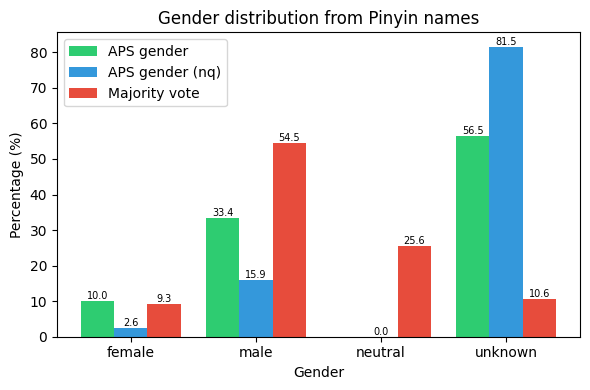

In [175]:
fig, ax = plot_gender_comparison(
    data_gender_pinyin,
    method_order=["gender_clean", "gender_nq_clean", "major_label"],
    method_labels={
        "gender_clean": "APS gender",
        "gender_nq_clean": "APS gender (nq)",
        "major_label": "Majority vote",
    },
    xlabel_order=["female", "male", "neutral", "unknown"],
    use_percentages=True,
    annotate_bars=True,
    annotate_kwargs={"fontsize": 7, "ha": "center", "va": "bottom"},
    legend_kwargs={"loc": "upper left"},
    title="Gender distribution from Pinyin names",
)
plt.show()

### Chinese characters

In [156]:
cols = ['givenname', 'pred', 'pred_label']
data_gender_chinese = data_gender.query("ch_givenname.notna()").copy()
data_gender_chinese = data_gender_chinese.merge(df_cnki_gender[cols], 
                                                how='left', 
                                                left_on='ch_givenname', 
                                                right_on='givenname', 
                                                suffixes=("_ours", "_cnki"))


data_gender_chinese.shape

(3165, 24)

In [157]:
data_gender_chinese.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin,givenname,pred,pred_label
0,232,['Wun-Hao Kang (康文豪)'],1,['unknown'],['-'],unknown,unknown,Wun-Hao Kang (康文豪),wun-hao kang,wun-hao,...,康文豪,['康 文豪'],康,文豪,kang wenhao,kang,wenhao,文豪,0.15908,male
1,294,"['Y. Liu', 'Y. Q. Liu', 'Y. Liu (刘育)', 'Y. L. ...",5,"['male', 'male', 'male', 'male', 'male']","['-', '-', '-', '-', '-']",male,unknown,Y. Liu (刘泱杰),y. liu,y.,...,刘泱杰,['刘 泱杰'],刘,泱杰,liu yangjie,liu,yangjie,NaN,NaN,NaN


In [158]:
chinese_cols = ['ch_givenname','gender_clean','gender_nq_clean','pred_label']
data_gender_chinese[chinese_cols]

,ch_givenname,gender_clean,gender_nq_clean,pred_label
0,文豪,unknown,unknown,male
1,泱杰,male,unknown,NaN
2,玉玺,male,unknown,neutral
3,育,male,unknown,neutral
4,玉孝,male,unknown,neutral
...,...,...,...,...
3160,万兵,unknown,unknown,male
3161,余刚,unknown,unknown,male
3162,喜光,unknown,unknown,male
3163,翔舟,unknown,unknown,male


In [159]:
data_gender_chinese.loc[:, 'gender_nq_clean'] = data_gender_chinese.gender_nq_clean.replace({'gf': 'female', 'gm': 'male'})
data_gender_chinese.loc[:, 'pred_label'] = data_gender_chinese.pred_label.replace({pd.NA: 'unknown'})
data_gender_chinese.gender_clean.unique(), data_gender_chinese.gender_nq_clean.unique(), data_gender_chinese.pred_label.unique()

(array(['unknown', 'male', 'female'], dtype=object),
 array(['unknown', 'male', 'female'], dtype=object),
 array(['male', 'unknown', 'neutral', 'female'], dtype=object))

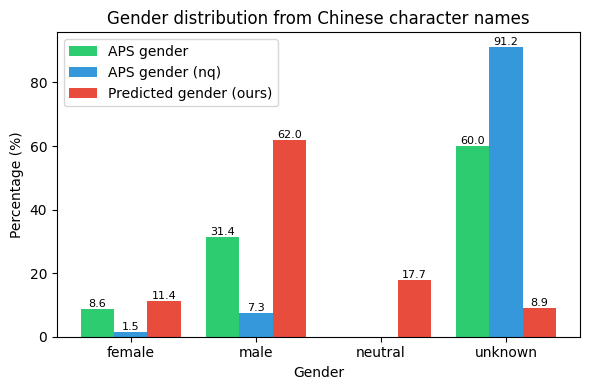

In [ ]:
fig, ax = plot_gender_comparison(
    data_gender_chinese,
    method_order=["gender_clean", "gender_nq_clean", "pred_label"],
    method_labels={
        "gender_clean": "APS gender",
        "gender_nq_clean": "APS gender (nq)",
        "pred_label": "Predicted gender (ours)",
    },
    xlabel_order=["female", "male", "neutral", "unknown"],
    colors=["#2ecc71", "#3498db", "#e74c3c"],
    use_percentages=True,
    annotate_bars=True,
    title="Gender distribution from Chinese character names",
)
plt.show()